# Rejection Class Analysis

In [2]:
import pandas as pd

# 1. CSV laden mit allen 4 Header-Zeilen (0 bis 3) und auf die 10 runs beschränken
df = pd.read_csv('../training/results/spatial/hierarchical_custom_ensemble_rf_stacking_ensemble_disagreement_rejection_spatial_breast_coarse/combined_result.csv', header=[0, 1, 2, 3])
df_runs = df.iloc[:10]

# 2. Klassen/Kategorien, die ausgeschlossen werden sollen
excluded_classes = [
    'Rejected',
    'macro avg',
    'weighted avg',
    'Overall',
]

# 3. Spalten filtern: 
# Ebene 1 = 'Classification Report'
# Ebene 2 = Klassenname (Sub-Category) -> soll nicht in excluded_classes sein
# Ebene 3 = Metrik -> soll genau 'f1-score' sein
f1_cols = [
    col for col in df.columns 
    if col[1] == 'Classification Report' 
    and col[2] not in excluded_classes 
    and col[3] == 'f1-score'
]

# 4. Macro F1 für jeden Run einzeln berechnen (Mittelwert über die Klassen pro Zeile)
macro_f1_per_run = df_runs[f1_cols].astype(float).mean(axis=1)

# 5. Den finalen Mean über alle 10 Runs hinweg berechnen
mean_macro_f1_overall = macro_f1_per_run.mean()

print("Macro F1 Werte der einzelnen 10 Runs (ohne Rejected Class):")
print(macro_f1_per_run)
print(f"\nFinaler Mean Macro F1 über alle 10 Runs hinweg: {mean_macro_f1_overall:.4f}")

Macro F1 Werte der einzelnen 10 Runs (ohne Rejected Class):
0    0.782706
1    0.787143
2    0.786886
3    0.781986
4    0.783996
5    0.785943
6    0.782753
7    0.781813
8    0.782713
9    0.785624
dtype: float64

Finaler Mean Macro F1 über alle 10 Runs hinweg: 0.7842


In [3]:
import pandas as pd

# 1. CSV laden mit allen 4 Header-Zeilen (0 bis 3) und auf die 10 runs beschränken
df = pd.read_csv('../training/results/spatial/hierarchical_custom_ensemble_rf_stacking_ensemble_disagreement_rejection_spatial_breast_fine_grained/combined_result.csv', header=[0, 1, 2, 3])
df_runs = df.iloc[:10]

# 2. Klassen/Kategorien, die ausgeschlossen werden sollen
excluded_classes = [
    'Rejected',
    'macro avg',
    'weighted avg',
    'Overall',
]

# 3. Spalten filtern: 
# Ebene 1 = 'Classification Report'
# Ebene 2 = Klassenname (Sub-Category) -> soll nicht in excluded_classes sein
# Ebene 3 = Metrik -> soll genau 'f1-score' sein
f1_cols = [
    col for col in df.columns 
    if col[1] == 'Classification Report' 
    and col[2] not in excluded_classes 
    and col[3] == 'f1-score'
]

# 4. Macro F1 für jeden Run einzeln berechnen (Mittelwert über die Klassen pro Zeile)
macro_f1_per_run = df_runs[f1_cols].astype(float).mean(axis=1)

# 5. Den finalen Mean über alle 10 Runs hinweg berechnen
mean_macro_f1_overall = macro_f1_per_run.mean()

print("Macro F1 Werte der einzelnen 10 Runs (ohne Rejected Class):")
print(macro_f1_per_run)
print(f"\nFinaler Mean Macro F1 über alle 10 Runs hinweg: {mean_macro_f1_overall:.4f}")

Macro F1 Werte der einzelnen 10 Runs (ohne Rejected Class):
0    0.392266
1    0.387455
2    0.391294
3    0.395177
4    0.386611
5    0.401992
6    0.389304
7    0.386362
8    0.390606
9    0.385684
dtype: float64

Finaler Mean Macro F1 über alle 10 Runs hinweg: 0.3907


## Fine-Grained-Analyse: Macro F1 pro Coarse-Zelltyp

**Ziel:** Untersuchen, welche Coarse-Zelltypen sich überhaupt sinnvoll weiter unterteilen lassen und bei welchen die feingranulare Klassifikation einbricht.

In [4]:
mapping = {
    # Epitheliale Zellen liegen im Fine-Grained-Datensatz bereits aggregiert vor.
    'Epithelial cell': ('Epithelial cell', 'Epithelial cell'),

    # Maligne / Epitheliale Zellen (Coarse & Fine gleich wegen hoher Donor-Spezifität)
    **{epi: ('Epithelial cell', 'Epithelial cell') for epi in [
        'epi_0', 'epi_1', 'epi_2', 'epi_3', 'epi_4', 'epi_5', 'epi_6',
        'epi_8', 'epi_13', 'epi_14', 'epi_15', 'epi_16', 'epi_17',
        'epi_18', 'epi_20', 'epi_22', 'epi_low_ent'
    ]},

    # T-Zellen
    'CD8_Tem': ('T cell', 'CD8_Tem'),
    'CD4_Tem': ('T cell', 'CD4_Tem'),
    'CD4_Treg': ('T cell', 'CD4_Treg'),
    'CD4_Naive': ('T cell', 'CD4_Naive'),
    'CD8_Tex': ('T cell', 'CD8_Tex'),
    'CD8_Isg': ('T cell', 'CD8_Isg'),
    'T_Prolif.': ('T cell', 'T_Prolif.'),
    'CD4_Tfh': ('T cell', 'CD4_Tfh'),
    'CD4_Th': ('T cell', 'CD4_Th'),

    # NK-Zellen
    'NK': ('Natural killer cell', 'NK'),
    'NK_rNK': ('Natural killer cell', 'NK_rNK'),
    'NK_Cyto.': ('Natural killer cell', 'NK_Cyto.'),

    # B-Zellen & Plasma-Zellen
    'Plasma_IgG': ('Plasma cell', 'Plasma_IgG'),
    'B_ACB': ('B cell', 'B_ACB'),
    'B_Naive': ('B cell', 'B_Naive'),
    'B_Cell': ('B cell', 'B_Cell'),
    'B_IFIT': ('B cell', 'B_IFIT'),
    'B_GCB': ('B cell', 'B_GCB'),

    # Myeloische Zellen
    'Mac/Mono': ('Myeloid cell', 'Mac/Mono'),
    'cDC2': ('Myeloid cell', 'cDC2'),
    'Mac_RTM_LA': ('Myeloid cell', 'Mac_RTM_LA'),
    'Mac_RTM_IFN': ('Myeloid cell', 'Mac_RTM_IFN'),
    'Mac_LA': ('Myeloid cell', 'Mac_LA'),
    'Mac_RTM_MT': ('Myeloid cell', 'Mac_RTM_MT'),
    'Mac_IFN': ('Myeloid cell', 'Mac_IFN'),
    'Mac_Anti.': ('Myeloid cell', 'Mac_Anti.'),
    'Mac_ES': ('Myeloid cell', 'Mac_ES'),
    'pDC': ('Myeloid cell', 'pDC'),
    'mDC': ('Myeloid cell', 'mDC'),
    'cDC1': ('Myeloid cell', 'cDC1'),
    'Mast': ('Myeloid cell', 'Mast'),

    # Stromale Zellen / CAFs
    'CAFs (COL11A1+)': ('Stromal cell', 'CAFs (COL11A1+)'),
    'CAFs (LAMP5)': ('Stromal cell', 'CAFs (LAMP5)'),
    'CAFs (PI16+)': ('Stromal cell', 'CAFs (PI16+)'),
    'CAFs (DPT+)': ('Stromal cell', 'CAFs (DPT+)'),
    'CAFs (CA12+)': ('Stromal cell', 'CAFs (CA12+)'),
    'PCs (ECM)': ('Stromal cell', 'PCs (ECM)'),
    'VSMC': ('Stromal cell', 'VSMC'),
    'Myofibroblast': ('Stromal cell', 'Myofibroblast'),
    'Prolif Stromal': ('Stromal cell', 'Prolif Stromal'),

    # Endothelzellen
    'Endo Imm.': ('Endothelial cell', 'Endo Imm.'),
    'Endo Ven.': ('Endothelial cell', 'Endo Ven.'),
    'Endo Capil.': ('Endothelial cell', 'Endo Capil.'),
    'Endo Arter.': ('Endothelial cell', 'Endo Arter.'),
    'Endo Lymph.': ('Endothelial cell', 'Endo Lymph.'),
}


In [5]:
import numpy as np

base_path = (
    '../training/results/spatial/'
    'hierarchical_custom_ensemble_rf_stacking_ensemble_disagreement_rejection_spatial_breast_'
)

fine_df = pd.read_csv(base_path + 'fine_grained/combined_result.csv', header=[0, 1, 2, 3]).iloc[:10]
coarse_df = pd.read_csv(base_path + 'coarse/combined_result.csv', header=[0, 1, 2, 3]).iloc[:10]

excluded_classes = ['Rejected', 'macro avg', 'weighted avg', 'Overall', 'Total_Accuracy']

fine_classes = sorted({
    col[2] for col in fine_df.columns
    if col[1] == 'Classification Report'
    and col[2] not in excluded_classes
    and col[3] == 'f1-score'
})

unmapped = sorted(set(fine_classes) - set(mapping))
assert not unmapped, f'Fine-Grained-Klassen ohne Coarse-Mapping: {unmapped}'

# Nur Klassen verwenden, die es im Fine-Grained-Datensatz tatsächlich gibt.
# Die epi_*-Einträge im Mapping bleiben für andere Datensätze erhalten.
fine_classes = [c for c in fine_classes if c in mapping]


def classification_metric(df, cls, metric):
    return df[('In-Distribution', 'Classification Report', cls, metric)].astype(float)


def f1_frame(classes):
    cols = [('In-Distribution', 'Classification Report', c, 'f1-score') for c in classes]
    return fine_df[cols].astype(float)


class_records = []
for fine_cls in fine_classes:
    f1 = classification_metric(fine_df, fine_cls, 'f1-score')
    class_records.append({
        'Coarse-Zelltyp': mapping[fine_cls][0],
        'Fine-Zelltyp': fine_cls,
        'F1 (Mean)': f1.mean(),
        'F1 (Std)': f1.std(),
        'Support': classification_metric(fine_df, fine_cls, 'support').iloc[0],
    })

class_stats = pd.DataFrame(class_records)

MIN_SUPPORT = 50

summary_records = []
for coarse_cls in sorted(class_stats['Coarse-Zelltyp'].unique()):
    subset = class_stats[class_stats['Coarse-Zelltyp'] == coarse_cls]

    # Macro F1 pro Run -> Mittelwert und Streuung über die 10 Runs
    macro_per_run = f1_frame(subset['Fine-Zelltyp']).mean(axis=1)

    frequent = subset[subset['Support'] >= MIN_SUPPORT]
    if len(frequent) > 0:
        macro_frequent_per_run = f1_frame(frequent['Fine-Zelltyp']).mean(axis=1)
        macro_frequent_mean = macro_frequent_per_run.mean()
    else:
        macro_frequent_mean = np.nan

    weights = subset.set_index('Fine-Zelltyp')['Support']
    per_run = f1_frame(subset['Fine-Zelltyp'])
    per_run.columns = subset['Fine-Zelltyp'].tolist()
    weighted_per_run = per_run.mul(weights, axis=1).sum(axis=1) / weights.sum()

    coarse_per_run = classification_metric(coarse_df, coarse_cls, 'f1-score')

    weakest = subset.loc[subset['F1 (Mean)'].idxmin()]
    strongest = subset.loc[subset['F1 (Mean)'].idxmax()]

    if len(subset) == 1:
        category = 'keine Unterteilung'
    elif macro_frequent_mean >= 0.60:
        category = 'gut'
    elif macro_frequent_mean >= 0.45:
        category = 'mittel'
    else:
        category = 'problematisch'

    summary_records.append({
        'Coarse-Zelltyp': coarse_cls,
        'Fine-Klassen': len(subset),
        'Support': int(subset['Support'].sum()),
        'Macro F1 (fine)': macro_per_run.mean(),
        'Std (Runs)': macro_per_run.std(),
        'Macro F1 (Support >= 50)': macro_frequent_mean,
        'Weighted F1': weighted_per_run.mean(),
        'Schwaechste Klasse': f"{weakest['Fine-Zelltyp']} ({weakest['F1 (Mean)']:.2f})",
        'Staerkste Klasse': f"{strongest['Fine-Zelltyp']} ({strongest['F1 (Mean)']:.2f})",
        'Macro F1 (coarse)': coarse_per_run.mean(),
        'Delta (fine - coarse)': macro_per_run.mean() - coarse_per_run.mean(),
        'Einordnung': category,
    })

summary = pd.DataFrame(summary_records).sort_values('Macro F1 (fine)').reset_index(drop=True)
summary.insert(0, 'Rang', np.arange(1, len(summary) + 1))

print('Fine-Grained-Performance pro Coarse-Zelltyp')
print('(sortiert nach Macro F1 der Fine-Grained-Klassen, schlechteste Gruppe zuerst)')
print('Schwellen der Einordnung: gut >= 0.60, mittel >= 0.45, problematisch < 0.45')
print('Basis der Einordnung: Macro F1 (Support >= 50)\n')

numeric_cols = [
    'Macro F1 (fine)', 'Std (Runs)', 'Macro F1 (Support >= 50)',
    'Weighted F1', 'Macro F1 (coarse)', 'Delta (fine - coarse)',
]
printable = summary.copy()
for col in numeric_cols:
    printable[col] = printable[col].map(lambda v: f'{v:+.3f}' if col.startswith('Delta') else f'{v:.3f}')
print(printable.to_string(index=False))


Fine-Grained-Performance pro Coarse-Zelltyp
(sortiert nach Macro F1 der Fine-Grained-Klassen, schlechteste Gruppe zuerst)
Schwellen der Einordnung: gut >= 0.60, mittel >= 0.45, problematisch < 0.45
Basis der Einordnung: Macro F1 (Support >= 50)

 Rang      Coarse-Zelltyp  Fine-Klassen  Support Macro F1 (fine) Std (Runs) Macro F1 (Support >= 50) Weighted F1     Schwaechste Klasse       Staerkste Klasse Macro F1 (coarse) Delta (fine - coarse)         Einordnung
    1              B cell             5     3032           0.172      0.008                    0.172       0.204           B_GCB (0.00)          B_IFIT (0.41)             0.744                -0.572      problematisch
    2 Natural killer cell             3     1768           0.190      0.007                    0.190       0.220          NK_rNK (0.04)              NK (0.29)             0.336                -0.147      problematisch
    3              T cell             9    15281           0.332      0.007                    0.374

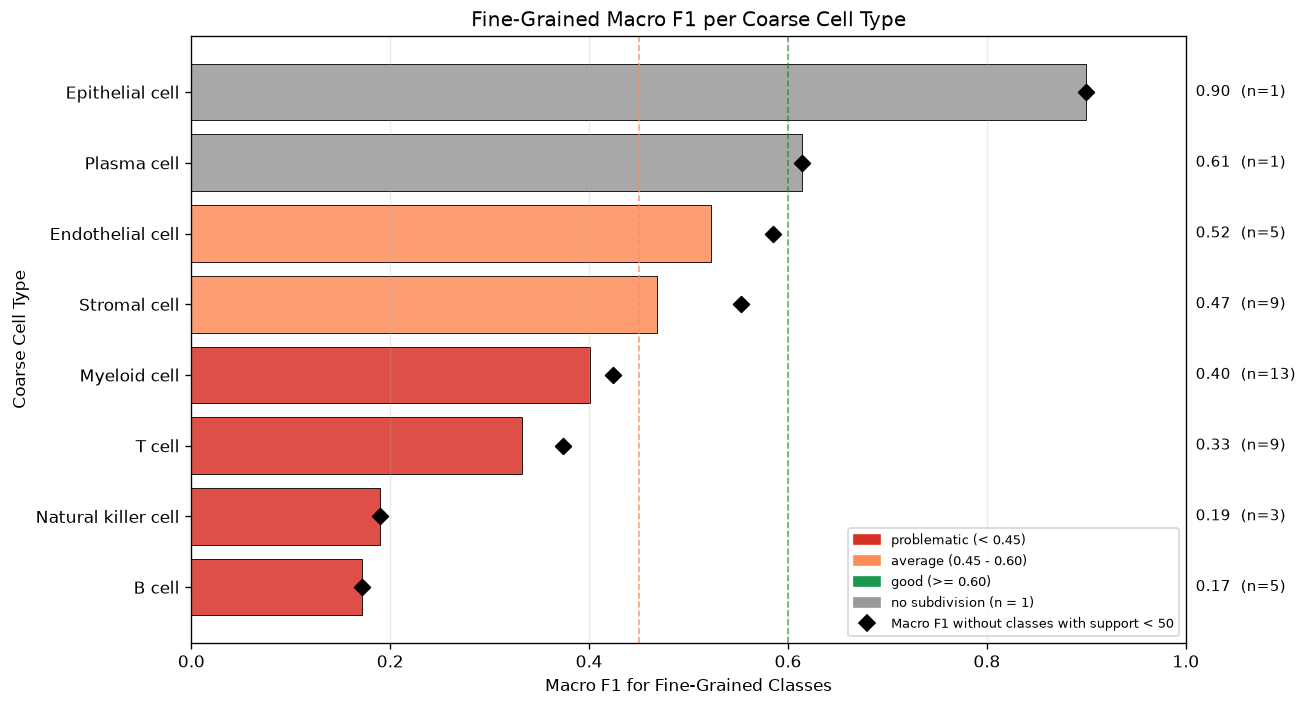

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.rcParams['figure.dpi'] = 120

category_colors = {
    'problematisch': '#d73027',
    'mittel': '#fc8d59',
    'gut': '#1a9850',
    'keine Unterteilung': '#999999',
}

plot_df = summary.sort_values('Macro F1 (fine)', ascending=True)
colors = [category_colors[c] for c in plot_df['Einordnung']]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(
    plot_df['Coarse-Zelltyp'],
    plot_df['Macro F1 (fine)'],
    color=colors,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.6,
)

ax.scatter(
    plot_df['Macro F1 (Support >= 50)'],
    plot_df['Coarse-Zelltyp'],
    marker='D',
    s=45,
    color='black',
    zorder=5,
    label='Macro F1 ohne Klassen mit Support < 50',
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    ax.text(
        1.01,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Macro F1 (fine)']:.2f}  (n={int(row['Fine-Klassen'])})",
        transform=ax.get_yaxis_transform(),
        va='center',
        fontsize=9,
        clip_on=False,
    )

ax.axvline(0.60, color='green', linestyle='--', linewidth=1, alpha=0.6)
ax.axvline(0.45, color='#fc8d59', linestyle='--', linewidth=1, alpha=0.8)
ax.set_xlim(0, 1.0)
ax.set_xlabel('Macro F1 for Fine-Grained Classes')
ax.set_ylabel('Coarse Cell Type')
ax.set_title(
    'Fine-Grained Macro F1 per Coarse Cell Type'
)
ax.grid(axis='x', alpha=0.25)

legend_handles = [
    mpatches.Patch(color=category_colors['problematisch'], label='problematic (< 0.45)'),
    mpatches.Patch(color=category_colors['mittel'], label='average (0.45 - 0.60)'),
    mpatches.Patch(color=category_colors['gut'], label='good (>= 0.60)'),
    mpatches.Patch(color=category_colors['keine Unterteilung'], label='no subdivision (n = 1)'),
    plt.Line2D([], [], marker='D', color='black', linestyle='None', markersize=7,
               label='Macro F1 without classes with support < 50'),
]
ax.legend(handles=legend_handles, loc='lower right', fontsize=8)

plt.tight_layout()
plt.savefig('figures/sparse_fine_grained_macro_f1_per_coarse_cell_type.pdf', format='pdf', bbox_inches='tight')
plt.savefig('figures/sparse_fine_grained_macro_f1_per_coarse_cell_type.png')

plt.show()

## Detailansicht der Fine-Grained-Klassen

In [6]:
class_table = class_stats.copy()
group_order = summary.set_index('Coarse-Zelltyp')['Macro F1 (fine)']
class_table['Gruppen-Rang'] = class_table['Coarse-Zelltyp'].map(
    summary.set_index('Coarse-Zelltyp')['Rang']
)
class_table = class_table.sort_values(['Gruppen-Rang', 'F1 (Mean)'], ascending=[True, True])

class_table['Hinweis'] = np.where(
    class_table['Support'] < MIN_SUPPORT, 'selten (Support < 50)', ''
)
class_table['Support'] = class_table['Support'].astype(int)

print('Fine-Grained-Klassen, gruppiert nach Coarse-Zelltyp')
print('(Gruppen nach Macro F1 aufsteigend, innerhalb der Gruppe schwaechste Klasse zuerst)\n')

class_print = class_table[['Coarse-Zelltyp', 'Fine-Zelltyp', 'F1 (Mean)', 'F1 (Std)', 'Support', 'Hinweis']].copy()
class_print['F1 (Mean)'] = class_print['F1 (Mean)'].map(lambda v: f'{v:.3f}')
class_print['F1 (Std)'] = class_print['F1 (Std)'].map(lambda v: f'{v:.3f}')
print(class_print.to_string(index=False))


Fine-Grained-Klassen, gruppiert nach Coarse-Zelltyp
(Gruppen nach Macro F1 aufsteigend, innerhalb der Gruppe schwaechste Klasse zuerst)

     Coarse-Zelltyp    Fine-Zelltyp F1 (Mean) F1 (Std)  Support               Hinweis
             B cell           B_GCB     0.000    0.000      451                      
             B cell          B_Cell     0.001    0.002      697                      
             B cell         B_Naive     0.071    0.048      379                      
             B cell           B_ACB     0.375    0.026      832                      
             B cell          B_IFIT     0.412    0.008      673                      
Natural killer cell          NK_rNK     0.036    0.015      433                      
Natural killer cell        NK_Cyto.     0.244    0.021      253                      
Natural killer cell              NK     0.288    0.007     1082                      
             T cell          CD4_Th     0.000    0.000        3 selten (Support < 50)
   

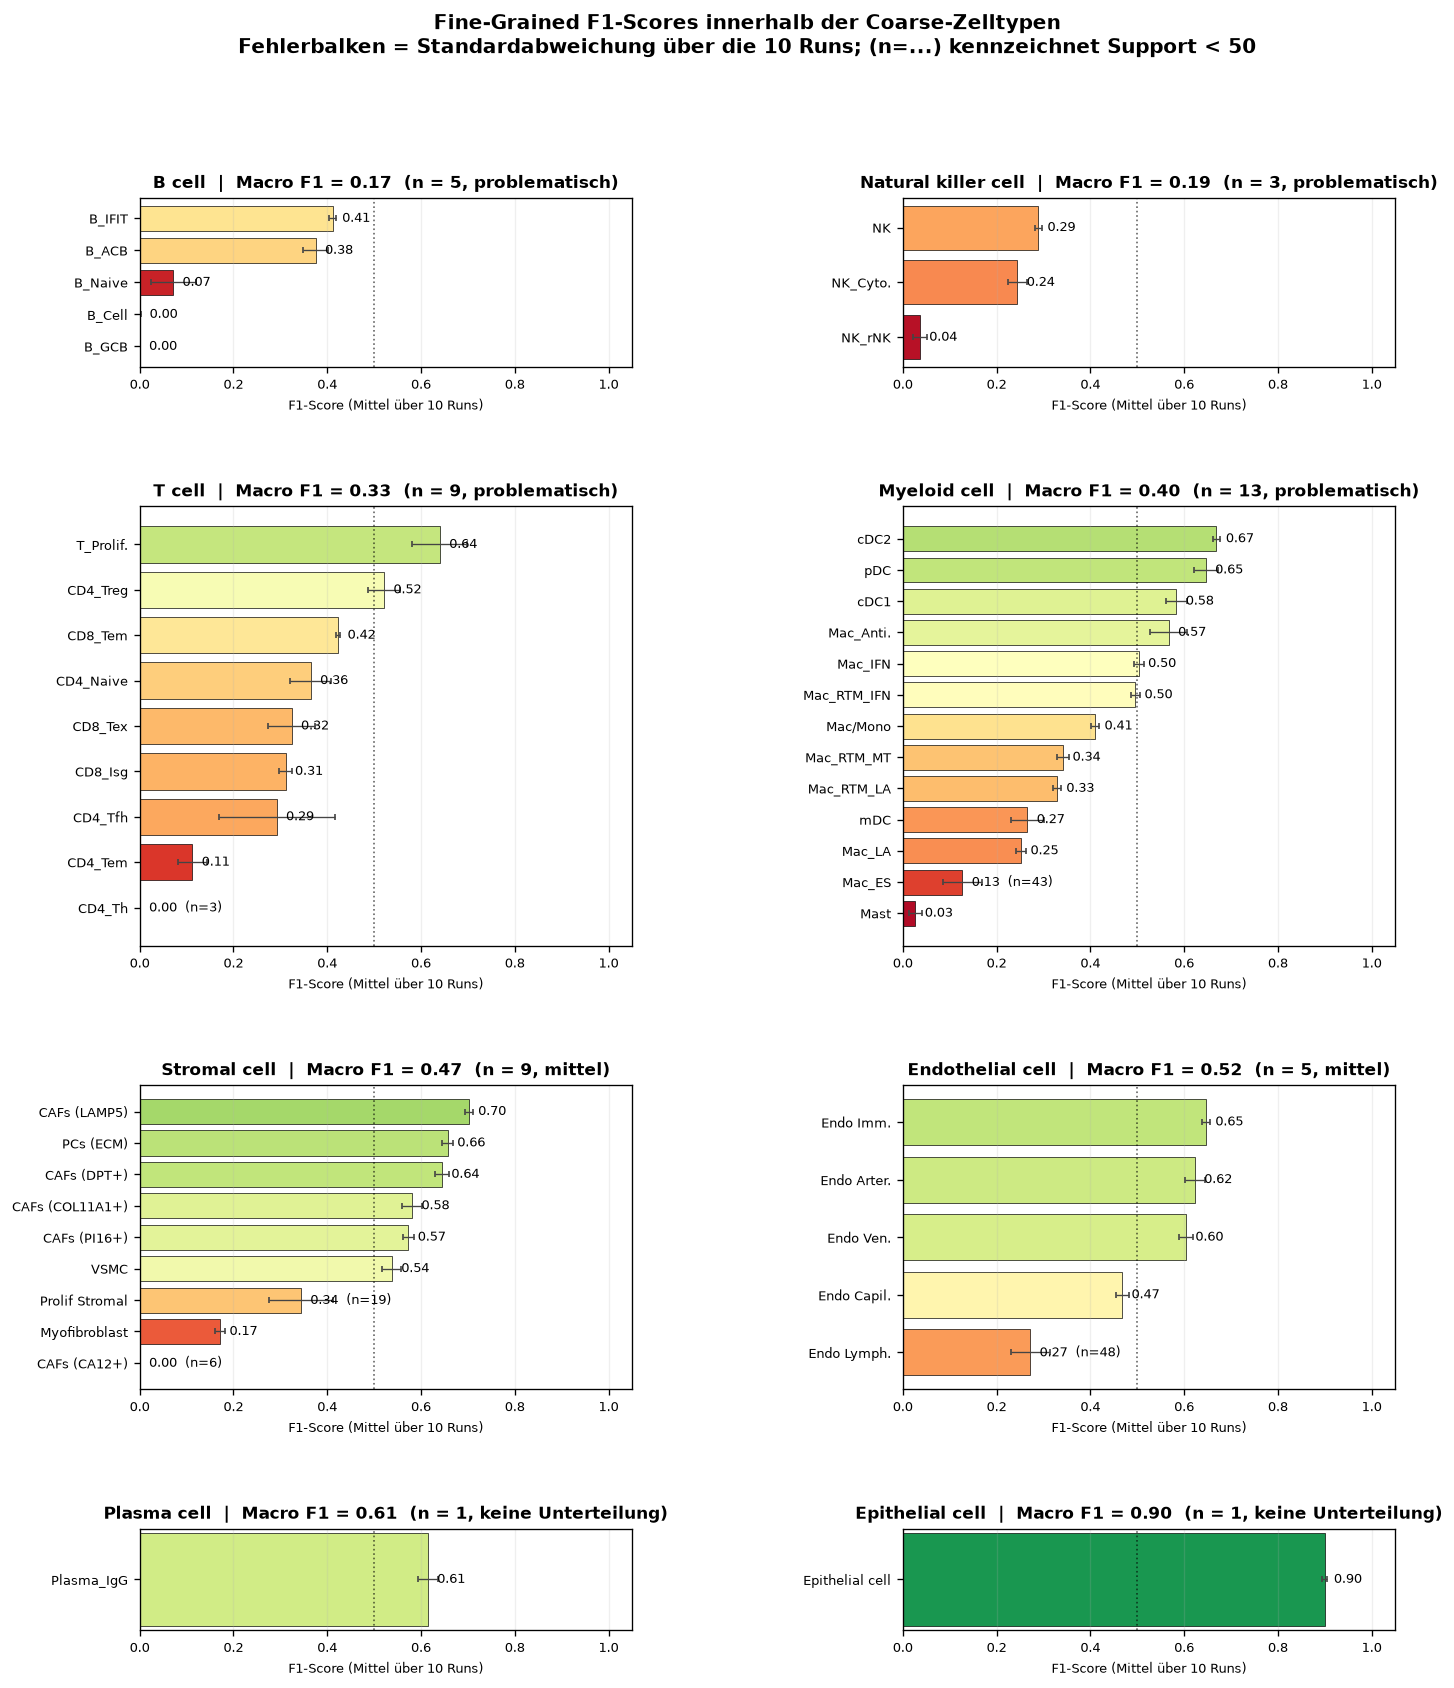

In [7]:
groups = list(summary['Coarse-Zelltyp'])

n_cols = 2
n_rows = int(np.ceil(len(groups) / n_cols))

# Hoehe jeder Zeile an die groesste Klassenzahl der beiden Facetten anpassen
row_heights = []
for row in range(n_rows):
    row_groups = groups[row * n_cols:(row + 1) * n_cols]
    row_heights.append(max(
        max(len(class_stats[class_stats['Coarse-Zelltyp'] == g]) for g in row_groups),
        3,
    ))

fig = plt.figure(figsize=(13.5, 0.45 * sum(row_heights) + 2.0))
gs = fig.add_gridspec(n_rows, n_cols, height_ratios=row_heights, hspace=0.55, wspace=0.55)

for idx, coarse_cls in enumerate(groups):
    ax = fig.add_subplot(gs[idx // n_cols, idx % n_cols])
    subset = class_stats[class_stats['Coarse-Zelltyp'] == coarse_cls].sort_values('F1 (Mean)')
    row = summary[summary['Coarse-Zelltyp'] == coarse_cls].iloc[0]

    colors = [plt.cm.RdYlGn(v) for v in subset['F1 (Mean)']]
    bars = ax.barh(
        subset['Fine-Zelltyp'],
        subset['F1 (Mean)'],
        xerr=subset['F1 (Std)'],
        color=colors,
        edgecolor='black',
        linewidth=0.4,
        error_kw={'ecolor': '#444444', 'elinewidth': 0.8, 'capsize': 2},
    )

    for bar, (_, cls_row) in zip(bars, subset.iterrows()):
        label = f"{cls_row['F1 (Mean)']:.2f}"
        if cls_row['Support'] < MIN_SUPPORT:
            label += f"  (n={int(cls_row['Support'])})"
        ax.text(
            min(bar.get_width() + 0.02, 0.98),
            bar.get_y() + bar.get_height() / 2,
            label,
            va='center',
            fontsize=8,
        )

    ax.axvline(0.5, color='black', linestyle=':', linewidth=1, alpha=0.6)
    ax.set_xlim(0, 1.05)
    ax.set_xlabel('F1-Score (Mittel über 10 Runs)', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    ax.set_title(
        f"{coarse_cls}  |  Macro F1 = {row['Macro F1 (fine)']:.2f}  "
        f"(n = {int(row['Fine-Klassen'])}, {row['Einordnung']})",
        fontsize=10,
        fontweight='bold',
    )
    ax.grid(axis='x', alpha=0.2)

# Leere Facetten ausblenden
for idx in range(len(groups), n_rows * n_cols):
    fig.add_subplot(gs[idx // n_cols, idx % n_cols]).axis('off')

fig.suptitle(
    'Fine-Grained F1-Scores innerhalb der Coarse-Zelltypen\n'
    'Fehlerbalken = Standardabweichung über die 10 Runs; (n=...) kennzeichnet Support < 50',
    fontsize=12,
    fontweight='bold',
)
plt.show()


## Zusammenfassende Einordnung

In [8]:
print('AUTOMATISCHE EINORDNUNG')
print('=' * 80)
print('Basis: Macro F1 über Fine-Klassen mit Support >= 50')
print('Schwellen: gut >= 0.60 | mittel 0.45 - 0.60 | problematisch < 0.45\n')

for category in ['gut', 'mittel', 'problematisch']:
    subset = summary[summary['Einordnung'] == category].sort_values(
        'Macro F1 (Support >= 50)', ascending=False
    )
    print(f'{category.upper()} ({len(subset)} Coarse-Zelltypen):')
    if len(subset) == 0:
        print('  -')
    for _, row in subset.iterrows():
        print(
            f"  - {row['Coarse-Zelltyp']:<22} "
            f"Macro F1 = {row['Macro F1 (fine)']:.2f}, "
            f"ohne seltene Klassen = {row['Macro F1 (Support >= 50)']:.2f}, "
            f"Delta zu Coarse = {row['Delta (fine - coarse)']:+.2f}"
        )
    print()

no_subdivision = summary[summary['Fine-Klassen'] == 1]
if len(no_subdivision) > 0:
    print('KEINE UNTERTEILUNG IM DATENSATZ:')
    for _, row in no_subdivision.iterrows():
        print(
            f"  - {row['Coarse-Zelltyp']:<22} "
            f"nur {row['Fine-Klassen']} Fine-Klasse(n); "
            f"F1 = {row['Macro F1 (fine)']:.2f}, daher kein Nachweis einer feinen Trennung"
        )
    print()

print('GROESSTER PERFORMANCE-VERLUST DURCH DIE UNTERTEILUNG:')
print('(Coarse -> Fine, sortiert nach Delta)')
for _, row in summary.sort_values('Delta (fine - coarse)').iterrows():
    if row['Fine-Klassen'] == 1:
        continue
    print(
        f"  - {row['Coarse-Zelltyp']:<22} "
        f"{row['Macro F1 (coarse)']:.2f} -> {row['Macro F1 (fine)']:.2f} "
        f"({row['Delta (fine - coarse)']:+.2f})"
    )
print()

drivers = class_stats[
    (class_stats['F1 (Mean)'] < 0.30) & (class_stats['Support'] >= MIN_SUPPORT)
].sort_values('F1 (Mean)')
print('FINE-KLASSEN MIT F1 < 0.30 UND SUPPORT >= 50 (Haupttreiber der Probleme):')
if len(drivers) == 0:
    print('  -')
for _, row in drivers.iterrows():
    print(
        f"  - {row['Fine-Zelltyp']:<22} "
        f"(Coarse: {row['Coarse-Zelltyp']:<18}) "
        f"F1 = {row['F1 (Mean)']:.2f}, Support = {int(row['Support'])}"
    )


AUTOMATISCHE EINORDNUNG
Basis: Macro F1 über Fine-Klassen mit Support >= 50
Schwellen: gut >= 0.60 | mittel 0.45 - 0.60 | problematisch < 0.45

GUT (0 Coarse-Zelltypen):
  -

MITTEL (2 Coarse-Zelltypen):
  - Endothelial cell       Macro F1 = 0.52, ohne seltene Klassen = 0.59, Delta zu Coarse = -0.41
  - Stromal cell           Macro F1 = 0.47, ohne seltene Klassen = 0.55, Delta zu Coarse = -0.48

PROBLEMATISCH (4 Coarse-Zelltypen):
  - Myeloid cell           Macro F1 = 0.40, ohne seltene Klassen = 0.42, Delta zu Coarse = -0.52
  - T cell                 Macro F1 = 0.33, ohne seltene Klassen = 0.37, Delta zu Coarse = -0.54
  - Natural killer cell    Macro F1 = 0.19, ohne seltene Klassen = 0.19, Delta zu Coarse = -0.15
  - B cell                 Macro F1 = 0.17, ohne seltene Klassen = 0.17, Delta zu Coarse = -0.57

KEINE UNTERTEILUNG IM DATENSATZ:
  - Plasma cell            nur 1 Fine-Klasse(n); F1 = 0.61, daher kein Nachweis einer feinen Trennung
  - Epithelial cell        nur 1 Fine-Kla